Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202401.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202402.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202403.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202404.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202405.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202406.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202407.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202408.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202409.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202410.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202411.csv
Using: C:\Users\caral\OneDrive - KTH\SUPD\Year 2\AI in Transportation\202412.csv

Reading: 202401.csv

Readin

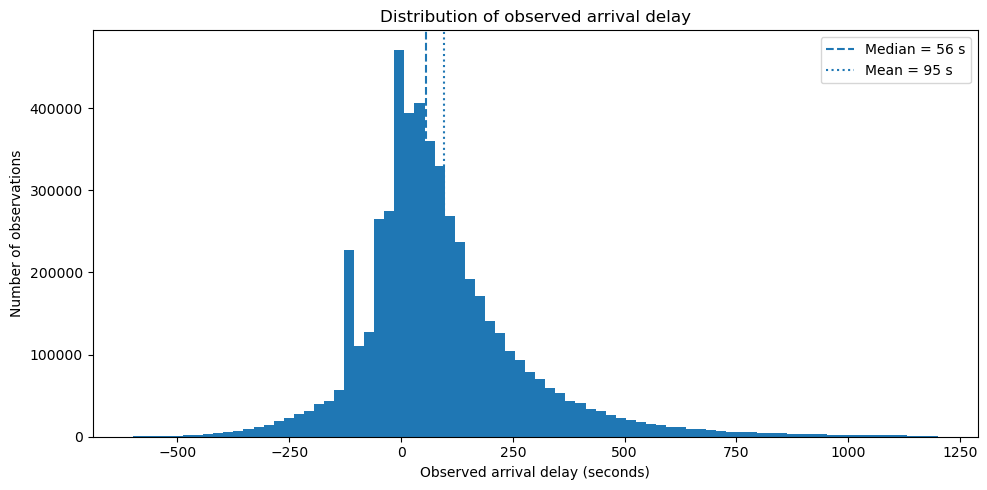

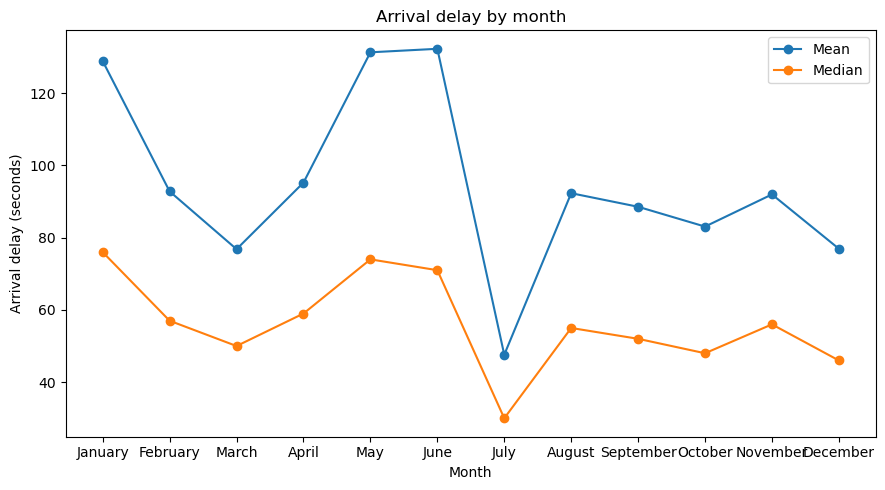

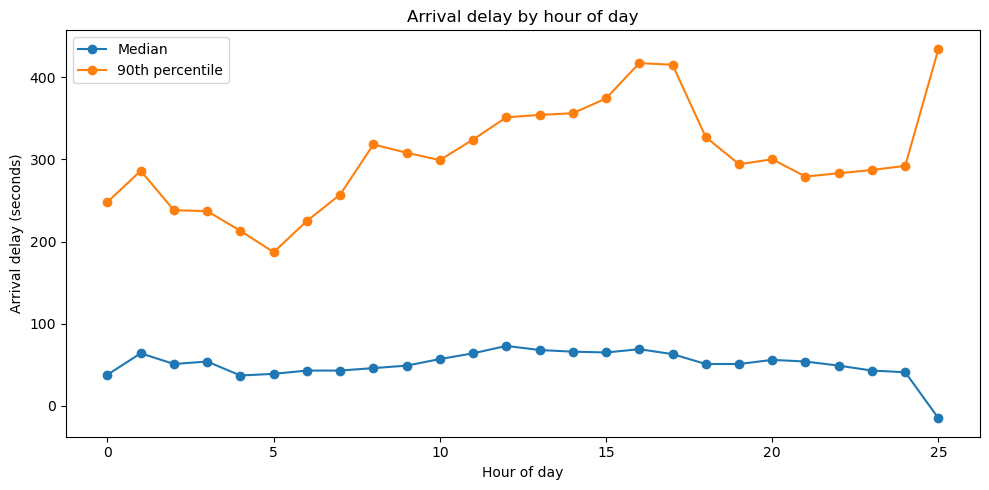

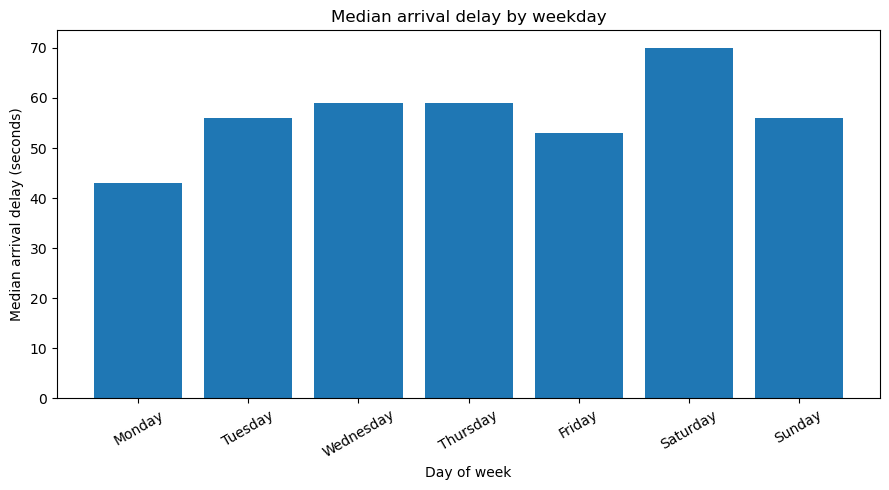

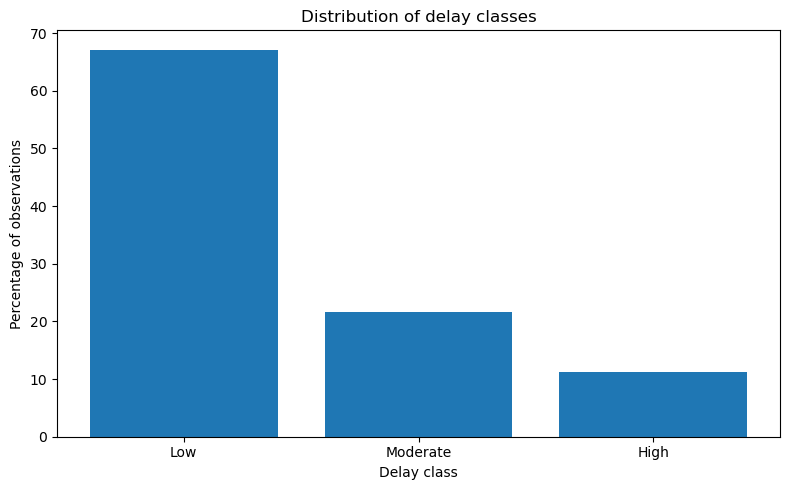

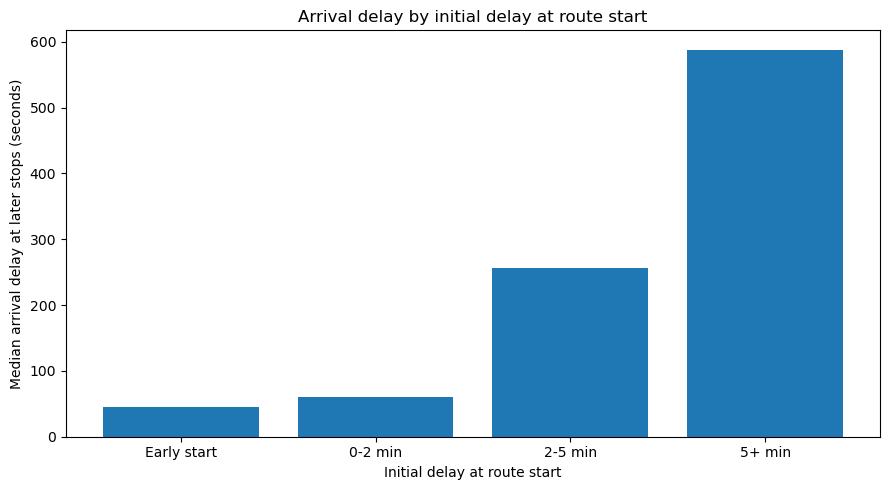

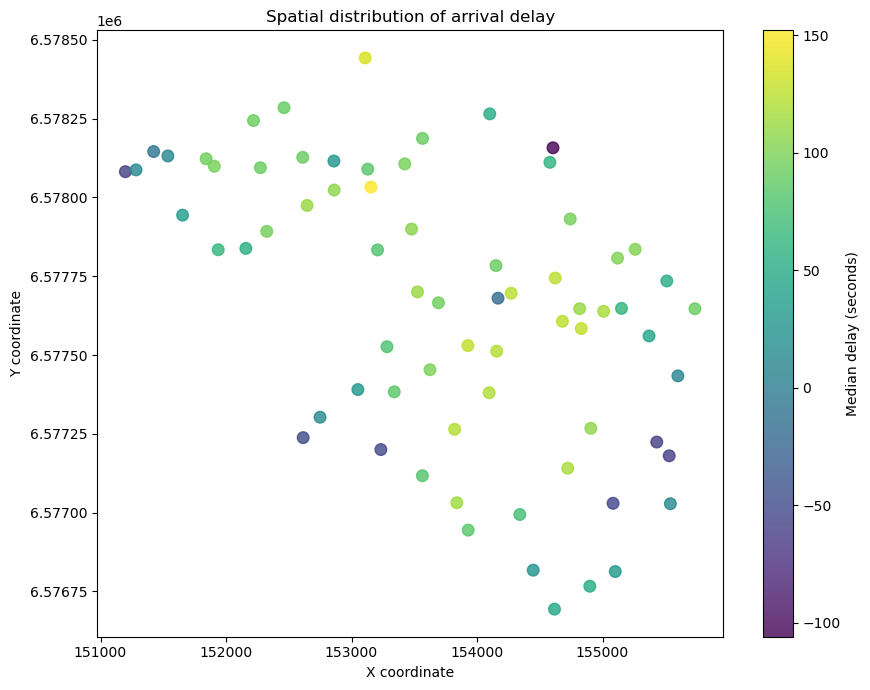

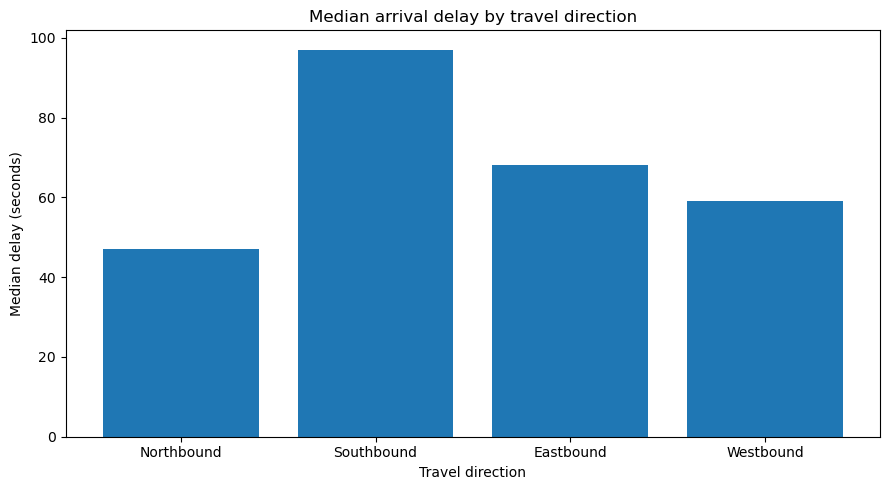

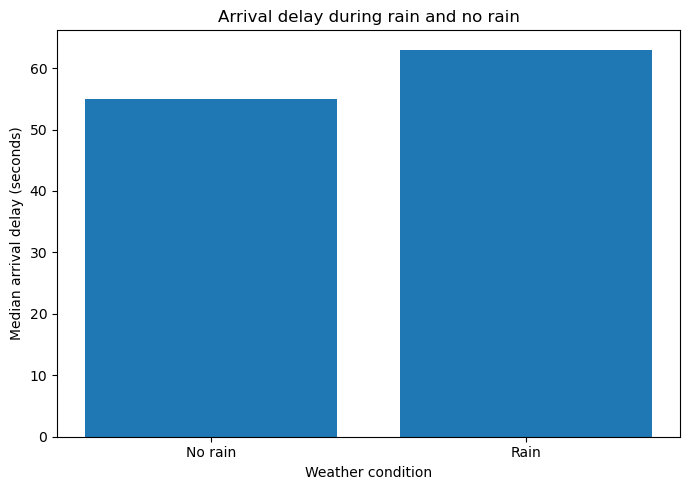

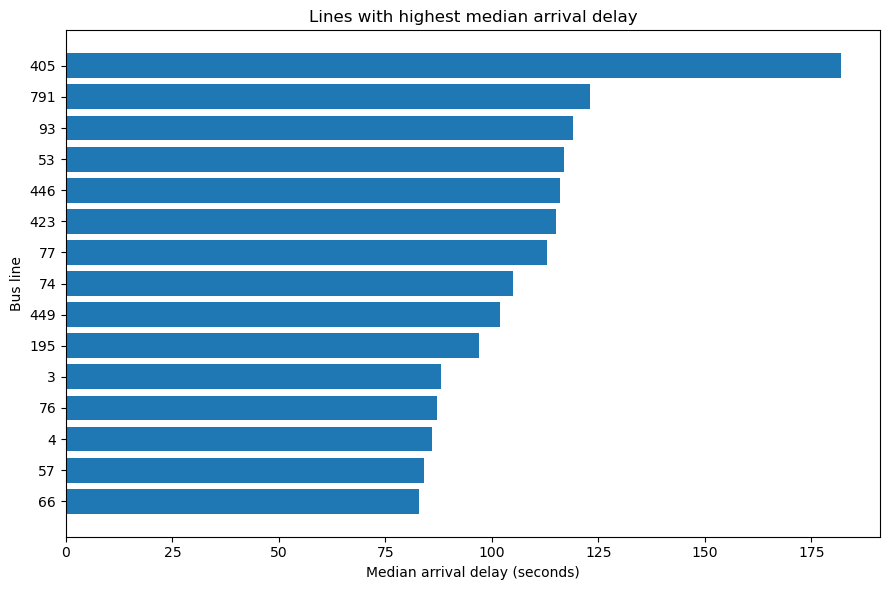

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# A. DESCRIPTIVE ANALYSIS - UPDATED DATASET
# ============================================================


# ------------------------------------------------------------
# 1. Project folder
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:/Users/caral/OneDrive - KTH/SUPD/Year 2/AI in Transportation"
)


months_to_use = ["202401", "202402", "202403", "202404", "202405", "202406", "202407", "202408", "202409", "202410", "202411", "202412"]


# ------------------------------------------------------------
# 2. Find updated monthly files
# ------------------------------------------------------------

# These columns identify the newer version of the dataset
new_columns = [
    "ini_delay",
    "rain-1",
    "rain-2",
    "temp-1",
    "temp-2",
    "date_format",
    "week_day"
]


files = []


for month in months_to_use:

    candidates = list(
        PROJECT_DIR.rglob(
            f"{month}*.csv"
        )
    )

    valid_candidates = []

    for candidate in candidates:

        try:

            header = pd.read_csv(
                candidate,
                nrows=0
            )

            if all(
                column in header.columns
                for column in new_columns
            ):

                valid_candidates.append(
                    candidate
                )

        except Exception:
            pass


    if len(valid_candidates) == 0:

        raise FileNotFoundError(
            f"\nNo updated file was found for {month}.\n"
            f"Searched inside:\n{PROJECT_DIR}"
        )


    file = sorted(
        valid_candidates,
        key=lambda x: len(x.name)
    )[0]


    files.append(
        file
    )


    print(
        "Using:",
        file
    )


# ============================================================
# 3. READ DATA
# ============================================================


columns = [

    # Time
    "date",
    "date_time",
    "month",
    "week_day",

    # Route / stop
    "LineID",
    "LineID_direction",
    "stop_sequence",
    "dist_traveled",
    "previous_StopAreaID",
    "observed_StopAreaID",

    # Delay
    "observed_arrival_delay",
    "ini_delay",

    # Current weather
    "rain",
    "temp",
    "hum",
    "wind_spe",

    # Weather 1 hour before
    "rain-1",
    "temp-1",
    "hum-1",
    "wind_spe-1",

    # Weather 2 hours before
    "rain-2",
    "temp-2",
    "hum-2",
    "wind_spe-2",

    # Coordinates
    "x_dest",
    "y_dest",
    "x_prevstop",
    "y_prevstop",
    "x_origin",
    "y_origin",

    # Direction variables
    "coming_from_origin",
    "coming_from_stop"
]


dataframes = []


for file in files:

    print(
        "\nReading:",
        file.name
    )

    month_data = pd.read_csv(
        file,
        usecols=columns,
        low_memory=False
    )

    dataframes.append(
        month_data
    )


df = pd.concat(
    dataframes,
    ignore_index=True
)


print(
    "\nTotal observations:",
    f"{len(df):,}"
)


# ============================================================
# 4. BASIC PREPROCESSING
# ============================================================


df["date_parsed"] = pd.to_datetime(
    df["date"].astype(str),
    format="%Y%m%d",
    errors="coerce"
)


df["weekday"] = (
    df["date_parsed"]
    .dt.day_name()
)


df["hour"] = pd.to_numeric(
    df["date_time"]
    .astype(str)
    .str.extract(
        r"_(\d{1,2})$"
    )[0],
    errors="coerce"
)


numeric_columns = [

    "observed_arrival_delay",
    "ini_delay",
    "dist_traveled",

    "rain",
    "temp",
    "hum",
    "wind_spe",

    "rain-1",
    "temp-1",
    "hum-1",
    "wind_spe-1",

    "rain-2",
    "temp-2",
    "hum-2",
    "wind_spe-2"
]


for column in numeric_columns:

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )


delay = (
    df["observed_arrival_delay"]
    .dropna()
)


# ============================================================
# 5. DATASET OVERVIEW
# ============================================================


print(
    "\n===================================================="
)

print(
    "DATASET OVERVIEW"
)

print(
    "===================================================="
)


print(
    "Number of observations:",
    f"{len(df):,}"
)


print(
    "Period:",
    df["date_parsed"].min().date(),
    "to",
    df["date_parsed"].max().date()
)


print(
    "Number of days:",
    df["date_parsed"].nunique()
)


print(
    "Number of stops:",
    df["observed_StopAreaID"].nunique()
)


print(
    "Number of routes:",
    df["LineID"].nunique()
)


print(
    "Number of line-directions:",
    df["LineID_direction"].nunique()
)


print(
    "Valid delay observations:",
    f"{delay.count():,}"
)


missing_delay = (
    df["observed_arrival_delay"]
    .isna()
    .sum()
)


print(
    "Missing delay observations:",
    f"{missing_delay:,}"
)


print(
    "Missing delay (%):",
    round(
        df["observed_arrival_delay"]
        .isna()
        .mean()
        * 100,
        2
    )
)


# ============================================================
# 6. OVERALL DELAY STATISTICS
# ============================================================


print(
    "\n===================================================="
)

print(
    "OVERALL DELAY STATISTICS"
)

print(
    "===================================================="
)


delay_table = pd.DataFrame({

    "Statistic": [
        "Mean",
        "Median",
        "25th percentile",
        "75th percentile",
        "90th percentile",
        "95th percentile",
        "99th percentile",
        "Minimum",
        "Maximum"
    ],

    "Delay (seconds)": [
        delay.mean(),
        delay.median(),
        delay.quantile(0.25),
        delay.quantile(0.75),
        delay.quantile(0.90),
        delay.quantile(0.95),
        delay.quantile(0.99),
        delay.min(),
        delay.max()
    ]

})


print(
    delay_table
    .round(2)
    .to_string(
        index=False
    )
)


early_percentage = (
    (delay < 0)
    .mean()
    * 100
)


late_5_min_percentage = (
    (delay >= 300)
    .mean()
    * 100
)


print(
    "\nEarly arrivals:",
    round(
        early_percentage,
        2
    ),
    "%"
)


print(
    "At least 5 minutes late:",
    round(
        late_5_min_percentage,
        2
    ),
    "%"
)


# ============================================================
# FIGURE 1 - DELAY HISTOGRAM
# ============================================================


delay_for_plot = delay[
    (delay >= -600)
    &
    (delay <= 1200)
]


plt.figure(
    figsize=(10, 5)
)


plt.hist(
    delay_for_plot,
    bins=80
)


plt.axvline(
    delay.median(),
    linestyle="--",
    label=f"Median = {delay.median():.0f} s"
)


plt.axvline(
    delay.mean(),
    linestyle=":",
    label=f"Mean = {delay.mean():.0f} s"
)


plt.xlabel(
    "Observed arrival delay (seconds)"
)


plt.ylabel(
    "Number of observations"
)


plt.title(
    "Distribution of observed arrival delay"
)


plt.legend()


plt.tight_layout()


# ============================================================
# 7. MONTHLY ANALYSIS
# ============================================================


monthly = (

    df.groupby(
        "month"
    )

    .agg(

        observations=(
            "observed_arrival_delay",
            "size"
        ),

        valid_delays=(
            "observed_arrival_delay",
            "count"
        ),

        mean_delay=(
            "observed_arrival_delay",
            "mean"
        ),

        median_delay=(
            "observed_arrival_delay",
            "median"
        ),

        p90_delay=(
            "observed_arrival_delay",
            lambda x:
            x.quantile(0.90)
        )

    )

    .reset_index()

)


monthly["missing_%"] = (

    (
        monthly["observations"]
        -
        monthly["valid_delays"]
    )

    /

    monthly["observations"]

    * 100

)


month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"

}


monthly["month_name"] = (
    monthly["month"]
    .map(
        month_names
    )
)


print(
    "\n===================================================="
)

print(
    "DELAY BY MONTH"
)

print(
    "===================================================="
)


print(

    monthly[
        [
            "month_name",
            "observations",
            "mean_delay",
            "median_delay",
            "p90_delay",
            "missing_%"
        ]
    ]

    .round(2)

    .to_string(
        index=False
    )

)


# ============================================================
# FIGURE 2 - MONTHLY DELAY
# ============================================================


plt.figure(
    figsize=(9, 5)
)


plt.plot(
    monthly["month_name"],
    monthly["mean_delay"],
    marker="o",
    label="Mean"
)


plt.plot(
    monthly["month_name"],
    monthly["median_delay"],
    marker="o",
    label="Median"
)


plt.xlabel(
    "Month"
)


plt.ylabel(
    "Arrival delay (seconds)"
)


plt.title(
    "Arrival delay by month"
)


plt.legend()


plt.tight_layout()


# ============================================================
# 8. HOURLY ANALYSIS
# ============================================================


hourly = (

    df.groupby(
        "hour"
    )

    .agg(

        observations=(
            "observed_arrival_delay",
            "count"
        ),

        mean_delay=(
            "observed_arrival_delay",
            "mean"
        ),

        median_delay=(
            "observed_arrival_delay",
            "median"
        ),

        p90_delay=(
            "observed_arrival_delay",
            lambda x:
            x.quantile(0.90)
        )

    )

    .reset_index()

)


print(
    "\n===================================================="
)

print(
    "DELAY BY HOUR"
)

print(
    "===================================================="
)


print(
    hourly
    .round(2)
    .to_string(
        index=False
    )
)


# ============================================================
# FIGURE 3 - HOURLY DELAY
# ============================================================


plt.figure(
    figsize=(10, 5)
)


plt.plot(
    hourly["hour"],
    hourly["median_delay"],
    marker="o",
    label="Median"
)


plt.plot(
    hourly["hour"],
    hourly["p90_delay"],
    marker="o",
    label="90th percentile"
)


plt.xlabel(
    "Hour of day"
)


plt.ylabel(
    "Arrival delay (seconds)"
)


plt.title(
    "Arrival delay by hour of day"
)


plt.legend()


plt.tight_layout()


# ============================================================
# 9. WEEKDAY ANALYSIS
# ============================================================


weekday_order = [

    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"

]


weekday = (

    df.groupby(
        "weekday"
    )

    .agg(

        observations=(
            "observed_arrival_delay",
            "count"
        ),

        mean_delay=(
            "observed_arrival_delay",
            "mean"
        ),

        median_delay=(
            "observed_arrival_delay",
            "median"
        ),

        p90_delay=(
            "observed_arrival_delay",
            lambda x:
            x.quantile(0.90)
        )

    )

    .reindex(
        weekday_order
    )

    .reset_index()

)


print(
    "\n===================================================="
)

print(
    "DELAY BY WEEKDAY"
)

print(
    "===================================================="
)


print(
    weekday
    .round(2)
    .to_string(
        index=False
    )
)


# ============================================================
# FIGURE 4 - WEEKDAY DELAY
# ============================================================


plt.figure(
    figsize=(9, 5)
)


plt.bar(
    weekday["weekday"],
    weekday["median_delay"]
)


plt.xlabel(
    "Day of week"
)


plt.ylabel(
    "Median arrival delay (seconds)"
)


plt.title(
    "Median arrival delay by weekday"
)


plt.xticks(
    rotation=30
)


plt.tight_layout()


# ============================================================
# 10. DELAY CLASSES
# ============================================================


conditions = [

    df["observed_arrival_delay"]
    < 120,

    (
        (
            df["observed_arrival_delay"]
            >= 120
        )
        &
        (
            df["observed_arrival_delay"]
            < 300
        )
    ),

    df["observed_arrival_delay"]
    >= 300

]


labels = [

    "Low",
    "Moderate",
    "High"

]


df["delay_class"] = np.select(

    conditions,
    labels,
    default="Missing"

)


delay_classes = (

    df[
        df["delay_class"]
        != "Missing"
    ]

    ["delay_class"]

    .value_counts()

    .reindex(
        [
            "Low",
            "Moderate",
            "High"
        ]
    )

    .reset_index()

)


delay_classes.columns = [

    "Delay class",
    "Observations"

]


delay_classes["Percentage"] = (

    delay_classes["Observations"]

    /

    delay_classes["Observations"]
    .sum()

    * 100

)


print(
    "\n===================================================="
)

print(
    "DELAY CLASS DISTRIBUTION"
)

print(
    "===================================================="
)


print(
    delay_classes
    .round(2)
    .to_string(
        index=False
    )
)


# ============================================================
# FIGURE 5 - DELAY CLASSES
# ============================================================


plt.figure(
    figsize=(8, 5)
)


plt.bar(
    delay_classes["Delay class"],
    delay_classes["Percentage"]
)


plt.xlabel(
    "Delay class"
)


plt.ylabel(
    "Percentage of observations"
)


plt.title(
    "Distribution of delay classes"
)


plt.tight_layout()


# ============================================================
# 11. INITIAL DELAY ANALYSIS
# ============================================================


# Group buses according to how late/early they started.

initial_delay_bins = [

    -np.inf,
    0,
    120,
    300,
    np.inf

]


initial_delay_labels = [

    "Early start",
    "0-2 min",
    "2-5 min",
    "5+ min"

]


df["initial_delay_group"] = pd.cut(

    df["ini_delay"],

    bins=initial_delay_bins,

    labels=initial_delay_labels,

    right=False

)


initial_delay_summary = (

    df.groupby(
        "initial_delay_group",
        observed=False
    )

    .agg(

        observations=(
            "observed_arrival_delay",
            "count"
        ),

        mean_arrival_delay=(
            "observed_arrival_delay",
            "mean"
        ),

        median_arrival_delay=(
            "observed_arrival_delay",
            "median"
        ),

        p90_arrival_delay=(
            "observed_arrival_delay",
            lambda x:
            x.quantile(0.90)
        )

    )

    .reset_index()

)


print(
    "\n===================================================="
)

print(
    "ARRIVAL DELAY BY INITIAL DELAY"
)

print(
    "===================================================="
)


print(
    initial_delay_summary
    .round(2)
    .to_string(
        index=False
    )
)


# Correlation between starting delay and later delay

initial_delay_data = (

    df[
        [
            "ini_delay",
            "observed_arrival_delay"
        ]
    ]

    .dropna()

)


initial_delay_correlation = (

    initial_delay_data[
        "ini_delay"
    ]

    .corr(
        initial_delay_data[
            "observed_arrival_delay"
        ]
    )

)


print(
    "\nCorrelation between initial delay and arrival delay:",
    round(
        initial_delay_correlation,
        3
    )
)


# ============================================================
# FIGURE 6 - INITIAL DELAY GROUPS
# ============================================================


plt.figure(
    figsize=(9, 5)
)


plt.bar(
    initial_delay_summary[
        "initial_delay_group"
    ].astype(str),

    initial_delay_summary[
        "median_arrival_delay"
    ]
)


plt.xlabel(
    "Initial delay at route start"
)


plt.ylabel(
    "Median arrival delay at later stops (seconds)"
)


plt.title(
    "Arrival delay by initial delay at route start"
)


plt.tight_layout()


# ============================================================
# 12. STOP / SPATIAL ANALYSIS
# ============================================================


stop_summary = (

    df.groupby(
        "observed_StopAreaID"
    )

    .agg(

        observations=(
            "observed_arrival_delay",
            "count"
        ),

        mean_delay=(
            "observed_arrival_delay",
            "mean"
        ),

        median_delay=(
            "observed_arrival_delay",
            "median"
        ),

        p90_delay=(
            "observed_arrival_delay",
            lambda x:
            x.quantile(0.90)
        ),

        x=(
            "x_dest",
            "median"
        ),

        y=(
            "y_dest",
            "median"
        )

    )

    .reset_index()

)


top_stops = (

    stop_summary[
        stop_summary["observations"]
        >= 1000
    ]

    .sort_values(
        "median_delay",
        ascending=False
    )

    .head(10)

)


print(
    "\n===================================================="
)

print(
    "10 STOPS WITH HIGHEST MEDIAN DELAY"
)

print(
    "===================================================="
)


print(

    top_stops[
        [
            "observed_StopAreaID",
            "observations",
            "mean_delay",
            "median_delay",
            "p90_delay"
        ]
    ]

    .round(2)

    .to_string(
        index=False
    )

)


# ============================================================
# FIGURE 7 - SPATIAL PATTERN
# ============================================================


spatial = stop_summary.dropna(
    subset=[
        "x",
        "y",
        "median_delay"
    ]
)


plt.figure(
    figsize=(9, 7)
)


points = plt.scatter(

    spatial["x"],
    spatial["y"],

    c=spatial["median_delay"],

    s=70,

    alpha=0.8

)


plt.colorbar(
    points,
    label="Median delay (seconds)"
)


plt.xlabel(
    "X coordinate"
)


plt.ylabel(
    "Y coordinate"
)


plt.title(
    "Spatial distribution of arrival delay"
)


plt.tight_layout()


# ============================================================
# 13. TRAVEL DIRECTION
# ============================================================


df["delta_x"] = (
    df["x_dest"]
    -
    df["x_origin"]
)


df["delta_y"] = (
    df["y_dest"]
    -
    df["y_origin"]
)


df["travel_direction"] = "Unknown"


north_south = (

    abs(
        df["delta_y"]
    )

    >=

    abs(
        df["delta_x"]
    )

)


east_west = (

    abs(
        df["delta_x"]
    )

    >

    abs(
        df["delta_y"]
    )

)


df.loc[

    north_south
    &
    (
        df["delta_y"]
        > 0
    ),

    "travel_direction"

] = "Northbound"


df.loc[

    north_south
    &
    (
        df["delta_y"]
        < 0
    ),

    "travel_direction"

] = "Southbound"


df.loc[

    east_west
    &
    (
        df["delta_x"]
        > 0
    ),

    "travel_direction"

] = "Eastbound"


df.loc[

    east_west
    &
    (
        df["delta_x"]
        < 0
    ),

    "travel_direction"

] = "Westbound"


direction_order = [

    "Northbound",
    "Southbound",
    "Eastbound",
    "Westbound"

]


direction_summary = (

    df[
        df["travel_direction"]
        != "Unknown"
    ]

    .groupby(
        "travel_direction"
    )

    .agg(

        observations=(
            "observed_arrival_delay",
            "count"
        ),

        mean_delay=(
            "observed_arrival_delay",
            "mean"
        ),

        median_delay=(
            "observed_arrival_delay",
            "median"
        ),

        p90_delay=(
            "observed_arrival_delay",
            lambda x:
            x.quantile(0.90)
        )

    )

    .reindex(
        direction_order
    )

    .reset_index()

)


print(
    "\n===================================================="
)

print(
    "DELAY BY TRAVEL DIRECTION"
)

print(
    "===================================================="
)


print(
    direction_summary
    .round(2)
    .to_string(
        index=False
    )
)


# ============================================================
# FIGURE 8 - TRAVEL DIRECTION
# ============================================================


plt.figure(
    figsize=(9, 5)
)


plt.bar(
    direction_summary["travel_direction"],
    direction_summary["median_delay"]
)


plt.xlabel(
    "Travel direction"
)


plt.ylabel(
    "Median delay (seconds)"
)


plt.title(
    "Median arrival delay by travel direction"
)


plt.tight_layout()


# ============================================================
# 14. CURRENT RAIN
# ============================================================


df["rain_condition"] = np.where(

    df["rain"] > 0,

    "Rain",

    "No rain"

)


rain_summary = (

    df.groupby(
        "rain_condition"
    )

    .agg(

        observations=(
            "observed_arrival_delay",
            "count"
        ),

        mean_delay=(
            "observed_arrival_delay",
            "mean"
        ),

        median_delay=(
            "observed_arrival_delay",
            "median"
        ),

        p90_delay=(
            "observed_arrival_delay",
            lambda x:
            x.quantile(0.90)
        )

    )

    .reset_index()

)


print(
    "\n===================================================="
)

print(
    "CURRENT RAIN VS NO RAIN"
)

print(
    "===================================================="
)


print(
    rain_summary
    .round(2)
    .to_string(
        index=False
    )
)


# ============================================================
# FIGURE 9 - RAIN VS NO RAIN
# ============================================================


plt.figure(
    figsize=(7, 5)
)


plt.bar(
    rain_summary["rain_condition"],
    rain_summary["median_delay"]
)


plt.xlabel(
    "Weather condition"
)


plt.ylabel(
    "Median arrival delay (seconds)"
)


plt.title(
    "Arrival delay during rain and no rain"
)


plt.tight_layout()


# ============================================================
# 15. WEATHER 1 AND 2 HOURS BEFORE
# ============================================================


weather_lag_results = []


rain_variables = {

    "Current": "rain",
    "1 hour before": "rain-1",
    "2 hours before": "rain-2"

}


for period, rain_variable in rain_variables.items():

    valid_weather = df[

        df[rain_variable].notna()

        &

        df["observed_arrival_delay"].notna()

    ].copy()


    rainy = valid_weather[
        valid_weather[rain_variable]
        > 0
    ]


    dry = valid_weather[
        valid_weather[rain_variable]
        <= 0
    ]


    weather_lag_results.append({

        "Weather time":
            period,

        "Rain observations":
            len(rainy),

        "Median delay during rain":
            rainy[
                "observed_arrival_delay"
            ].median(),

        "Median delay without rain":
            dry[
                "observed_arrival_delay"
            ].median(),

        "P90 delay during rain":
            rainy[
                "observed_arrival_delay"
            ].quantile(0.90)

    })


weather_lag_table = pd.DataFrame(
    weather_lag_results
)


print(
    "\n===================================================="
)

print(
    "RAIN CURRENT / 1 HOUR / 2 HOURS BEFORE"
)

print(
    "===================================================="
)


print(
    weather_lag_table
    .round(2)
    .to_string(
        index=False
    )
)


# ============================================================
# 16. TEMPERATURE
# ============================================================


temperature_bins = [

    -np.inf,
    0,
    10,
    20,
    np.inf

]


temperature_labels = [

    "<0°C",
    "0-9.9°C",
    "10-19.9°C",
    "20°C or more"

]


df["temperature_group"] = pd.cut(

    df["temp"],

    bins=temperature_bins,

    labels=temperature_labels,

    right=False

)


temperature_summary = (

    df.groupby(
        "temperature_group",
        observed=False
    )

    .agg(

        observations=(
            "observed_arrival_delay",
            "count"
        ),

        mean_delay=(
            "observed_arrival_delay",
            "mean"
        ),

        median_delay=(
            "observed_arrival_delay",
            "median"
        ),

        p90_delay=(
            "observed_arrival_delay",
            lambda x:
            x.quantile(0.90)
        )

    )

    .reset_index()

)


print(
    "\n===================================================="
)

print(
    "DELAY BY TEMPERATURE"
)

print(
    "===================================================="
)


print(
    temperature_summary
    .round(2)
    .to_string(
        index=False
    )
)


# ============================================================
# 17. WIND SPEED
# ============================================================


wind_bins = [

    -np.inf,
    3,
    6,
    np.inf

]


wind_labels = [

    "<3 m/s",
    "3-5.9 m/s",
    "6 m/s or more"

]


df["wind_group"] = pd.cut(

    df["wind_spe"],

    bins=wind_bins,

    labels=wind_labels,

    right=False

)


wind_summary = (

    df.groupby(
        "wind_group",
        observed=False
    )

    .agg(

        observations=(
            "observed_arrival_delay",
            "count"
        ),

        mean_delay=(
            "observed_arrival_delay",
            "mean"
        ),

        median_delay=(
            "observed_arrival_delay",
            "median"
        ),

        p90_delay=(
            "observed_arrival_delay",
            lambda x:
            x.quantile(0.90)
        )

    )

    .reset_index()

)


print(
    "\n===================================================="
)

print(
    "DELAY BY WIND SPEED"
)

print(
    "===================================================="
)


print(
    wind_summary
    .round(2)
    .to_string(
        index=False
    )
)


# ============================================================
# 18. BUS LINE ANALYSIS
# ============================================================


line_id = (
    df["LineID_direction"]
    .astype(str)
)


df["line"] = (

    line_id

    .str.slice(
        8,
        11
    )

    .str.lstrip(
        "0"
    )

    .replace(
        "",
        "0"
    )

)


line_summary = (

    df.groupby(
        "line"
    )

    .agg(

        observations=(
            "observed_arrival_delay",
            "count"
        ),

        mean_delay=(
            "observed_arrival_delay",
            "mean"
        ),

        median_delay=(
            "observed_arrival_delay",
            "median"
        ),

        p90_delay=(
            "observed_arrival_delay",
            lambda x:
            x.quantile(0.90)
        )

    )

    .reset_index()

)


top_lines = (

    line_summary[
        line_summary["observations"]
        >= 5000
    ]

    .sort_values(
        "median_delay",
        ascending=False
    )

    .head(15)

)


print(
    "\n===================================================="
)

print(
    "LINES WITH HIGHEST MEDIAN DELAY"
)

print(
    "===================================================="
)


print(
    top_lines
    .round(2)
    .to_string(
        index=False
    )
)


# ============================================================
# FIGURE 10 - BUS LINES
# ============================================================


plt.figure(
    figsize=(9, 6)
)


plt.barh(
    top_lines["line"].astype(str),
    top_lines["median_delay"]
)


plt.xlabel(
    "Median arrival delay (seconds)"
)


plt.ylabel(
    "Bus line"
)


plt.title(
    "Lines with highest median arrival delay"
)


plt.gca().invert_yaxis()


plt.tight_layout()


# ============================================================
# 19. MAIN PATTERNS
# ============================================================


highest_month = monthly.loc[
    monthly["median_delay"]
    .idxmax()
]


lowest_month = monthly.loc[
    monthly["median_delay"]
    .idxmin()
]


highest_direction = direction_summary.loc[
    direction_summary["median_delay"]
    .idxmax()
]


lowest_direction = direction_summary.loc[
    direction_summary["median_delay"]
    .idxmin()
]


print(
    "\n===================================================="
)

print(
    "MAIN PATTERNS FOUND"
)

print(
    "===================================================="
)


print(
    "\nHighest monthly median delay:",
    highest_month[
        "month_name"
    ],
    "-",
    round(
        highest_month[
            "median_delay"
        ],
        1
    ),
    "seconds"
)


print(
    "Lowest monthly median delay:",
    lowest_month[
        "month_name"
    ],
    "-",
    round(
        lowest_month[
            "median_delay"
        ],
        1
    ),
    "seconds"
)


print(
    "\nDirection with highest median delay:",
    highest_direction[
        "travel_direction"
    ],
    "-",
    round(
        highest_direction[
            "median_delay"
        ],
        1
    ),
    "seconds"
)


print(
    "Direction with lowest median delay:",
    lowest_direction[
        "travel_direction"
    ],
    "-",
    round(
        lowest_direction[
            "median_delay"
        ],
        1
    ),
    "seconds"
)


print(
    "\nInitial delay / arrival delay correlation:",
    round(
        initial_delay_correlation,
        3
    )
)


high_delay_percentage = (

    delay_classes.loc[

        delay_classes[
            "Delay class"
        ]
        == "High",

        "Percentage"

    ]

    .iloc[0]

)


print(
    "High-delay observations:",
    round(
        high_delay_percentage,
        2
    ),
    "%"
)


# Rain comparison in automatic summary

rain_row = rain_summary[
    rain_summary["rain_condition"]
    == "Rain"
]


no_rain_row = rain_summary[
    rain_summary["rain_condition"]
    == "No rain"
]


if (
    len(rain_row) > 0
    and
    len(no_rain_row) > 0
):

    print(
        "\nMedian delay during rain:",
        round(
            rain_row[
                "median_delay"
            ].iloc[0],
            1
        ),
        "seconds"
    )

    print(
        "Median delay without rain:",
        round(
            no_rain_row[
                "median_delay"
            ].iloc[0],
            1
        ),
        "seconds"
    )


print(
    "\n===================================================="
)

print(
    "DESCRIPTIVE ANALYSIS COMPLETE"
)

print(
    "===================================================="
)


# ============================================================
# 20. DISPLAY ALL FIGURES
# ============================================================


plt.show()

